# 04 - Évaluation sur toutes les données, attaque par attaque

On refait la comparaison avec **les 8 fichiers complets** (dataset_full) et on regarde, pour chaque type d'attaque, quelle part est détectée.

⚠️ Prérequis : le fichier `data/processed/dataset_full.joblib` doit exister (créé par le script de prétraitement complet).

In [1]:
import sys; sys.path.append('..')
import pandas as pd
from src import evaluate as ev
pd.set_option('display.width', 200)

## 1. Charger les données complètes
Le train est limité à 400 000 lignes (stratifié) pour tenir en mémoire ; **le test reste complet**.

In [2]:
X_train, y_train, X_test, y_test = ev.load_data(train_sample=400_000, path=ev.FULL_PATH)
ym_test = ev.load_test_labels(ev.FULL_PATH)
print('train:', X_train.shape, '| test:', X_test.shape)
print('part d attaques train:', round(y_train.mean(), 3), '| test:', round(y_test.mean(), 3))

train: (400000, 70) | test: (499596, 70)
part d attaques train: 0.17 | test: 0.17


## 2. Entraîner et comparer

In [3]:
table, preds, models = ev.run_all(X_train, y_train, X_test, y_test)
table

,precision,recall,f1,roc_auc,temps_entraînement_s
modèle,,,,,
Random Forest,0.9953,0.9971,0.9962,0.9999,32.7
XGBoost,0.9951,0.9991,0.9971,1.0000,10.2
Isolation Forest,0.7988,0.3881,0.5224,0.8080,4.9


## 3. Résultats par type de trafic
- **BENIGN** : part correctement classée comme normale.
- **Attaques** : part détectée (rappel). Regarde surtout les classes rares : Bot, Infiltration, Web Attack, Heartbleed, SQL Injection.

In [4]:
report = ev.per_class_report(ym_test, preds)
report

,n_test,Random Forest,XGBoost,Isolation Forest
classe,,,,
BENIGN,414451,0.9990,0.9990,0.9799
DoS Hulk,34592,0.9976,0.9997,0.8123
DDoS,25636,0.9995,0.9998,0.1625
PortScan,18219,0.9999,0.9999,0.0004
DoS GoldenEye,1999,0.9965,0.9980,0.0040
FTP-Patator,1148,0.9991,0.9991,0.0000
DoS slowloris,1079,0.9963,0.9972,0.5246
DoS Slowhttptest,1004,0.9890,0.9920,0.1713
SSH-Patator,642,0.9922,0.9953,0.0000


sauvegardé


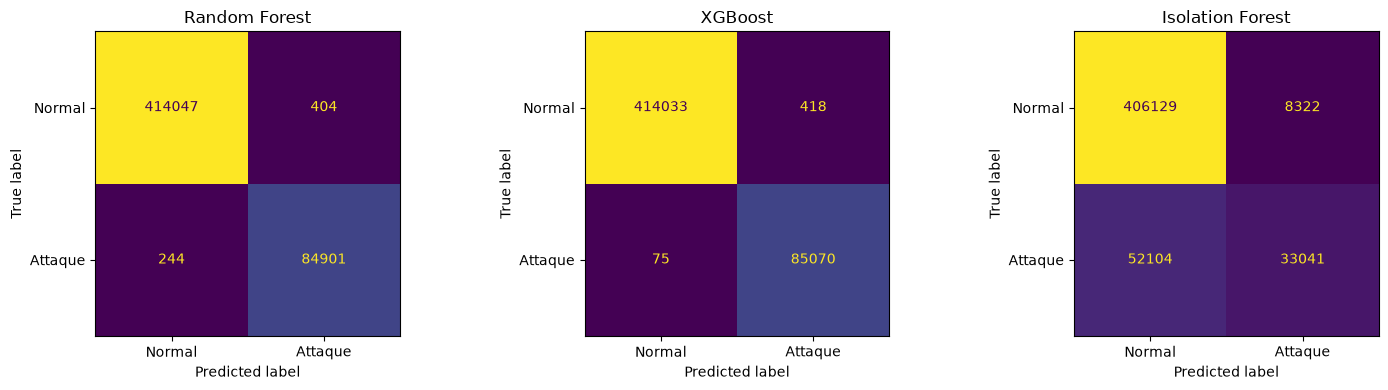

In [5]:
fig = ev.save_confusion_matrices(y_test, preds, out=ev.RESULTS_DIR / 'confusion_matrices_full.png')
report.to_csv('../results/per_class_report.csv')
table.to_csv('../results/model_comparison_full.csv')
print('sauvegardé')

## Observations
*(à compléter : quelles attaques sont bien détectées ? lesquelles sont ratées ? pourquoi ?)*

## Observations
- Sur les 8 fichiers complets (2 497 980 flux, 15 classes), XGBoost est le meilleur modèle : F1 = 0,997, rappel = 0,999, précision = 0,995. Random Forest est très proche (F1 = 0,996). Les deux détectent plus de 99,7 % des attaques.
- XGBoost s'entraîne en environ 10 s contre 28 s pour Random Forest : il est aussi plus rapide.
- Les fausses alertes sont rares : 99,9 % du trafic normal est correctement classé.
- Les attaques fréquentes (DoS Hulk, DDoS, PortScan, FTP-Patator, SSH-Patator) sont détectées à plus de 99 %.
- Bot : XGBoost détecte 93 % des flux contre 73 % pour Random Forest. Les flux de botnet ressemblent à du trafic normal, XGBoost les sépare mieux.
- Infiltration est la vraie faiblesse : seulement 1 flux sur 6 est détecté (17 %). L'attaquant se comporte comme un utilisateur normal, et il n'y a que 36 exemples dans tout le dataset.
- SQL Injection (4 flux de test) et Heartbleed (2 flux de test) sont trop rares pour tirer une conclusion : un score de 100 % sur 2 flux n'est pas significatif.
- Isolation Forest (non supervisé) est faible : rappel = 0,39, F1 = 0,52. Il rate presque entièrement PortScan, FTP-Patator et SSH-Patator, car ces flux ressemblent à du trafic normal. Avoir des exemples d'attaques améliore beaucoup la détection.
- Limites : le split train/test est aléatoire. En réalité, un IDS doit détecter des attaques de jours futurs. Un test avec un split par jour serait plus exigeant. De plus, l'entraînement utilise un sous-échantillon de 400 000 flux sur 2 millions.